In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

In [25]:
# Load datasets
penguins = sns.load_dataset("penguins")
tips = sns.load_dataset("tips")

print(penguins.head())
print(tips.head())

  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
3          NaN     NaN  
4       3450.0  Female  
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


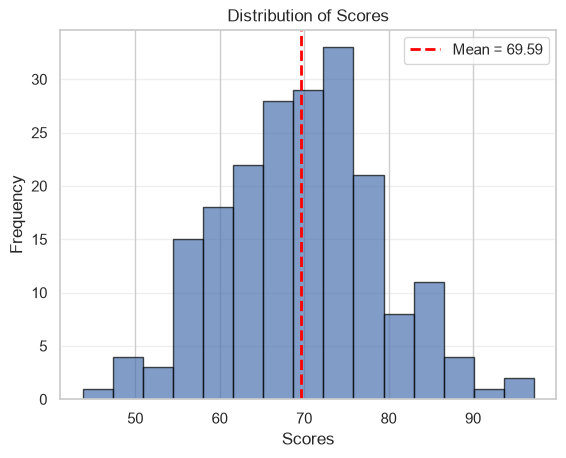

In [26]:
# Q1. 
# Generate random data
np.random.seed(42)
scores = np.random.normal(loc=70, scale=10, size=200)

# Calculate mean
mean_score = np.mean(scores)

# Plot histogram
plt.hist(scores, bins=15, edgecolor="black", alpha=0.7)

# Draw vertical line for mean
plt.axvline(
    mean_score,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_score:.2f}"
)

# Customize plot
plt.title("Distribution of Scores")
plt.xlabel("Scores")
plt.ylabel("Frequency")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

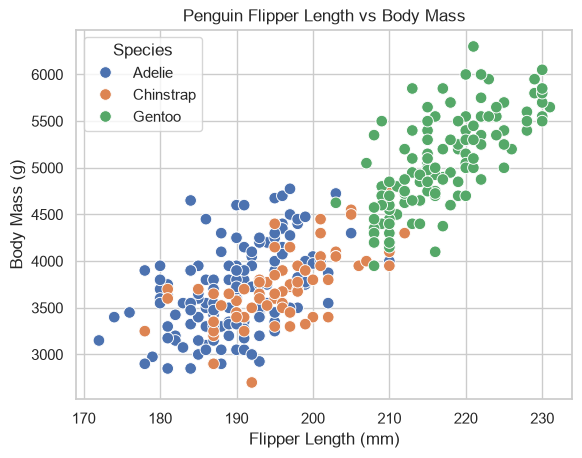

In [27]:
# Q2. 
# Scatter Plot
sns.scatterplot(
    data=penguins,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species",
    s=70
)

# Customize plot
plt.title("Penguin Flipper Length vs Body Mass")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (g)")
plt.legend(title="Species")

plt.show()

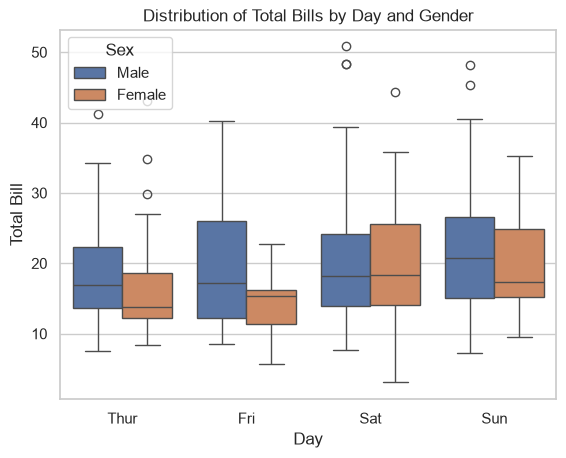

In [28]:
# Q3. 
# Create box plot
sns.boxplot(
    data=tips,
    x="day",
    y="total_bill",
    hue="sex"
)

# Customize plot
plt.title("Distribution of Total Bills by Day and Gender")
plt.xlabel("Day")
plt.ylabel("Total Bill")
plt.legend(title="Sex")

plt.show()

In [29]:
median_bill = tips.groupby(
    "day", observed=True
)["total_bill"].median()

print(median_bill)

print("\nDay with highest median bill:", median_bill.idxmax())

day
Thur    16.20
Fri     15.38
Sat     18.24
Sun     19.63
Name: total_bill, dtype: float64

Day with highest median bill: Sun


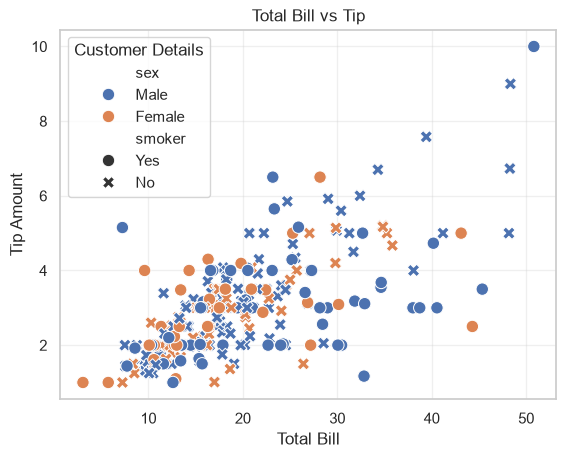

In [30]:
# Q4. 
# Scatter plot
sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="sex",
    style="smoker",
    s=80,
)

# Customize plot
plt.title("Total Bill vs Tip")
plt.xlabel("Total Bill")
plt.ylabel("Tip Amount")
plt.legend(title="Customer Details")
plt.grid(alpha=0.3)

plt.show()

In [31]:
# Calculate average tip
smoker_analysis = tips.groupby("smoker", observed=True)["tip"].mean()
print(smoker_analysis)

smoker
Yes    3.008710
No     2.991854
Name: tip, dtype: float64


In [32]:
tips["tip_percentage"] = (
    tips["tip"] / tips["total_bill"]
) * 100

smoker_stats = tips.groupby(
    "smoker", observed=True
).agg(
    average_tip=("tip", "mean"),
    average_bill=("total_bill", "mean"),
    average_tip_percentage=("tip_percentage", "mean")
)

print(smoker_stats.round(2))

        average_tip  average_bill  average_tip_percentage
smoker                                                   
Yes            3.01         20.76                   16.32
No             2.99         19.19                   15.93


In [33]:
# Q5.
# Heatmap
tips.head()
tip_pivot = tips.pivot_table(
    index="day",
    columns="time",
    values="tip",
    aggfunc="mean",
    observed=False
)

print(tip_pivot)

time     Lunch    Dinner
day                     
Thur  2.767705  3.000000
Fri   2.382857  2.940000
Sat        NaN  2.993103
Sun        NaN  3.255132


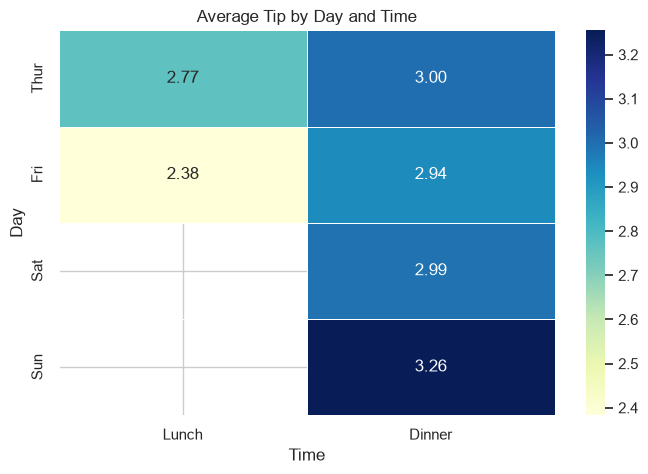

In [34]:
plt.figure(figsize=(8,5))

sns.heatmap(
    tip_pivot,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Average Tip by Day and Time")
plt.xlabel("Time")
plt.ylabel("Day")

plt.show()

In [35]:
best_day, best_time = tip_pivot.stack().idxmax()
best_tip = tip_pivot.stack().max()

print(f"Best day: {best_day}")
print(f"Best time: {best_time}")
print(f"Highest average tip: {best_tip:.2f}")

Best day: Sun
Best time: Dinner
Highest average tip: 3.26
